In [194]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from category_encoders import TargetEncoder 
import warnings
warnings.filterwarnings('ignore')

In [195]:
def data_loader(path):
    df = pd.read_csv(path)
    return df

path = '../data/raw/HomeTehran.csv'
df = data_loader(path=path)

df.head()

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
0,63,1,True,True,True,Shahran,1.850000e+09,61666.67
1,60,1,True,True,True,Shahran,1.850000e+09,61666.67
2,79,2,True,True,True,Pardis,5.500000e+08,18333.33
3,95,2,True,True,True,Shahrake Qods,9.025000e+08,30083.33
4,123,2,True,True,True,Shahrake Gharb,7.000000e+09,233333.33


In [196]:
df.shape

(3479, 8)

In [197]:
df.drop('Price(USD)' , axis=1 , inplace=True)

In [198]:
df.shape

(3479, 7)

In [199]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3479 entries, 0 to 3478
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Area       3479 non-null   object 
 1   Room       3479 non-null   int64  
 2   Parking    3479 non-null   bool   
 3   Warehouse  3479 non-null   bool   
 4   Elevator   3479 non-null   bool   
 5   Address    3456 non-null   object 
 6   Price      3479 non-null   float64
dtypes: bool(3), float64(1), int64(1), object(2)
memory usage: 119.0+ KB


In [200]:
df.describe()

,Room,Price
count,3479.000000,3.479000e+03
mean,2.079908,5.359023e+09
std,0.758275,8.099935e+09
min,0.000000,3.600000e+06
25%,2.000000,1.418250e+09
50%,2.000000,2.900000e+09
75%,2.000000,6.000000e+09
max,5.000000,9.240000e+10


In [201]:
df.isna().sum()

Area          0
Room          0
Parking       0
Warehouse     0
Elevator      0
Address      23
Price         0
dtype: int64

In [202]:
df.duplicated().sum()

np.int64(208)

In [203]:
df['Area'] = df['Area'].astype(str).str.replace(',' ,'').str.strip().astype('int64')
df['Elevator'] = df['Elevator'].astype('int8')
df['Warehouse'] = df['Warehouse'].astype('int8')
df['Room'] = df['Room'].astype('int8')
df['Parking'] = df['Parking'].astype('int8')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3479 entries, 0 to 3478
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Area       3479 non-null   int64  
 1   Room       3479 non-null   int8   
 2   Parking    3479 non-null   int8   
 3   Warehouse  3479 non-null   int8   
 4   Elevator   3479 non-null   int8   
 5   Address    3456 non-null   object 
 6   Price      3479 non-null   float64
dtypes: float64(1), int64(1), int8(4), object(1)
memory usage: 95.3+ KB


In [204]:
df.columns

Index(['Area', 'Room', 'Parking', 'Warehouse', 'Elevator', 'Address', 'Price'], dtype='object')

In [205]:
df.describe()

,Area,Room,Parking,Warehouse,Elevator,Price
count,3.479000e+03,3479.000000,3479.000000,3479.000000,3479.000000,3.479000e+03
mean,8.744000e+06,2.079908,0.847945,0.914631,0.787295,5.359023e+09
std,3.167266e+08,0.758275,0.359126,0.279471,0.409279,8.099935e+09
min,3.000000e+01,0.000000,0.000000,0.000000,0.000000,3.600000e+06
25%,6.900000e+01,2.000000,1.000000,1.000000,1.000000,1.418250e+09
50%,9.000000e+01,2.000000,1.000000,1.000000,1.000000,2.900000e+09
75%,1.200000e+02,2.000000,1.000000,1.000000,1.000000,6.000000e+09
max,1.616000e+10,5.000000,1.000000,1.000000,1.000000,9.240000e+10


In [206]:
df[df['Area'] > 900]

,Area,Room,Parking,Warehouse,Elevator,Address,Price
570,3310000000,2,1,1,1,Ostad Moein,3.310000e+09
709,16160000000,3,1,1,1,Pasdaran,1.616000e+10
807,1000,2,1,1,0,Damavand,7.000000e+09
1604,8400000000,2,1,1,1,Gheitarieh,8.700000e+09
1694,929,5,1,1,0,Zafar,8.000000e+10
2171,3600,2,0,0,0,Shahryar,9.720000e+09
2802,2550000000,2,1,1,1,Central Janatabad,2.550000e+09


In [207]:
df

,Area,Room,Parking,Warehouse,Elevator,Address,Price
0,63,1,1,1,1,Shahran,1.850000e+09
1,60,1,1,1,1,Shahran,1.850000e+09
2,79,2,1,1,1,Pardis,5.500000e+08
3,95,2,1,1,1,Shahrake Qods,9.025000e+08
4,123,2,1,1,1,Shahrake Gharb,7.000000e+09
...,...,...,...,...,...,...,...
3474,86,2,1,1,1,Southern Janatabad,3.500000e+09
3475,83,2,1,1,1,Niavaran,6.800000e+09
3476,75,2,0,0,0,Parand,3.650000e+08
3477,105,2,1,1,1,Dorous,5.600000e+09


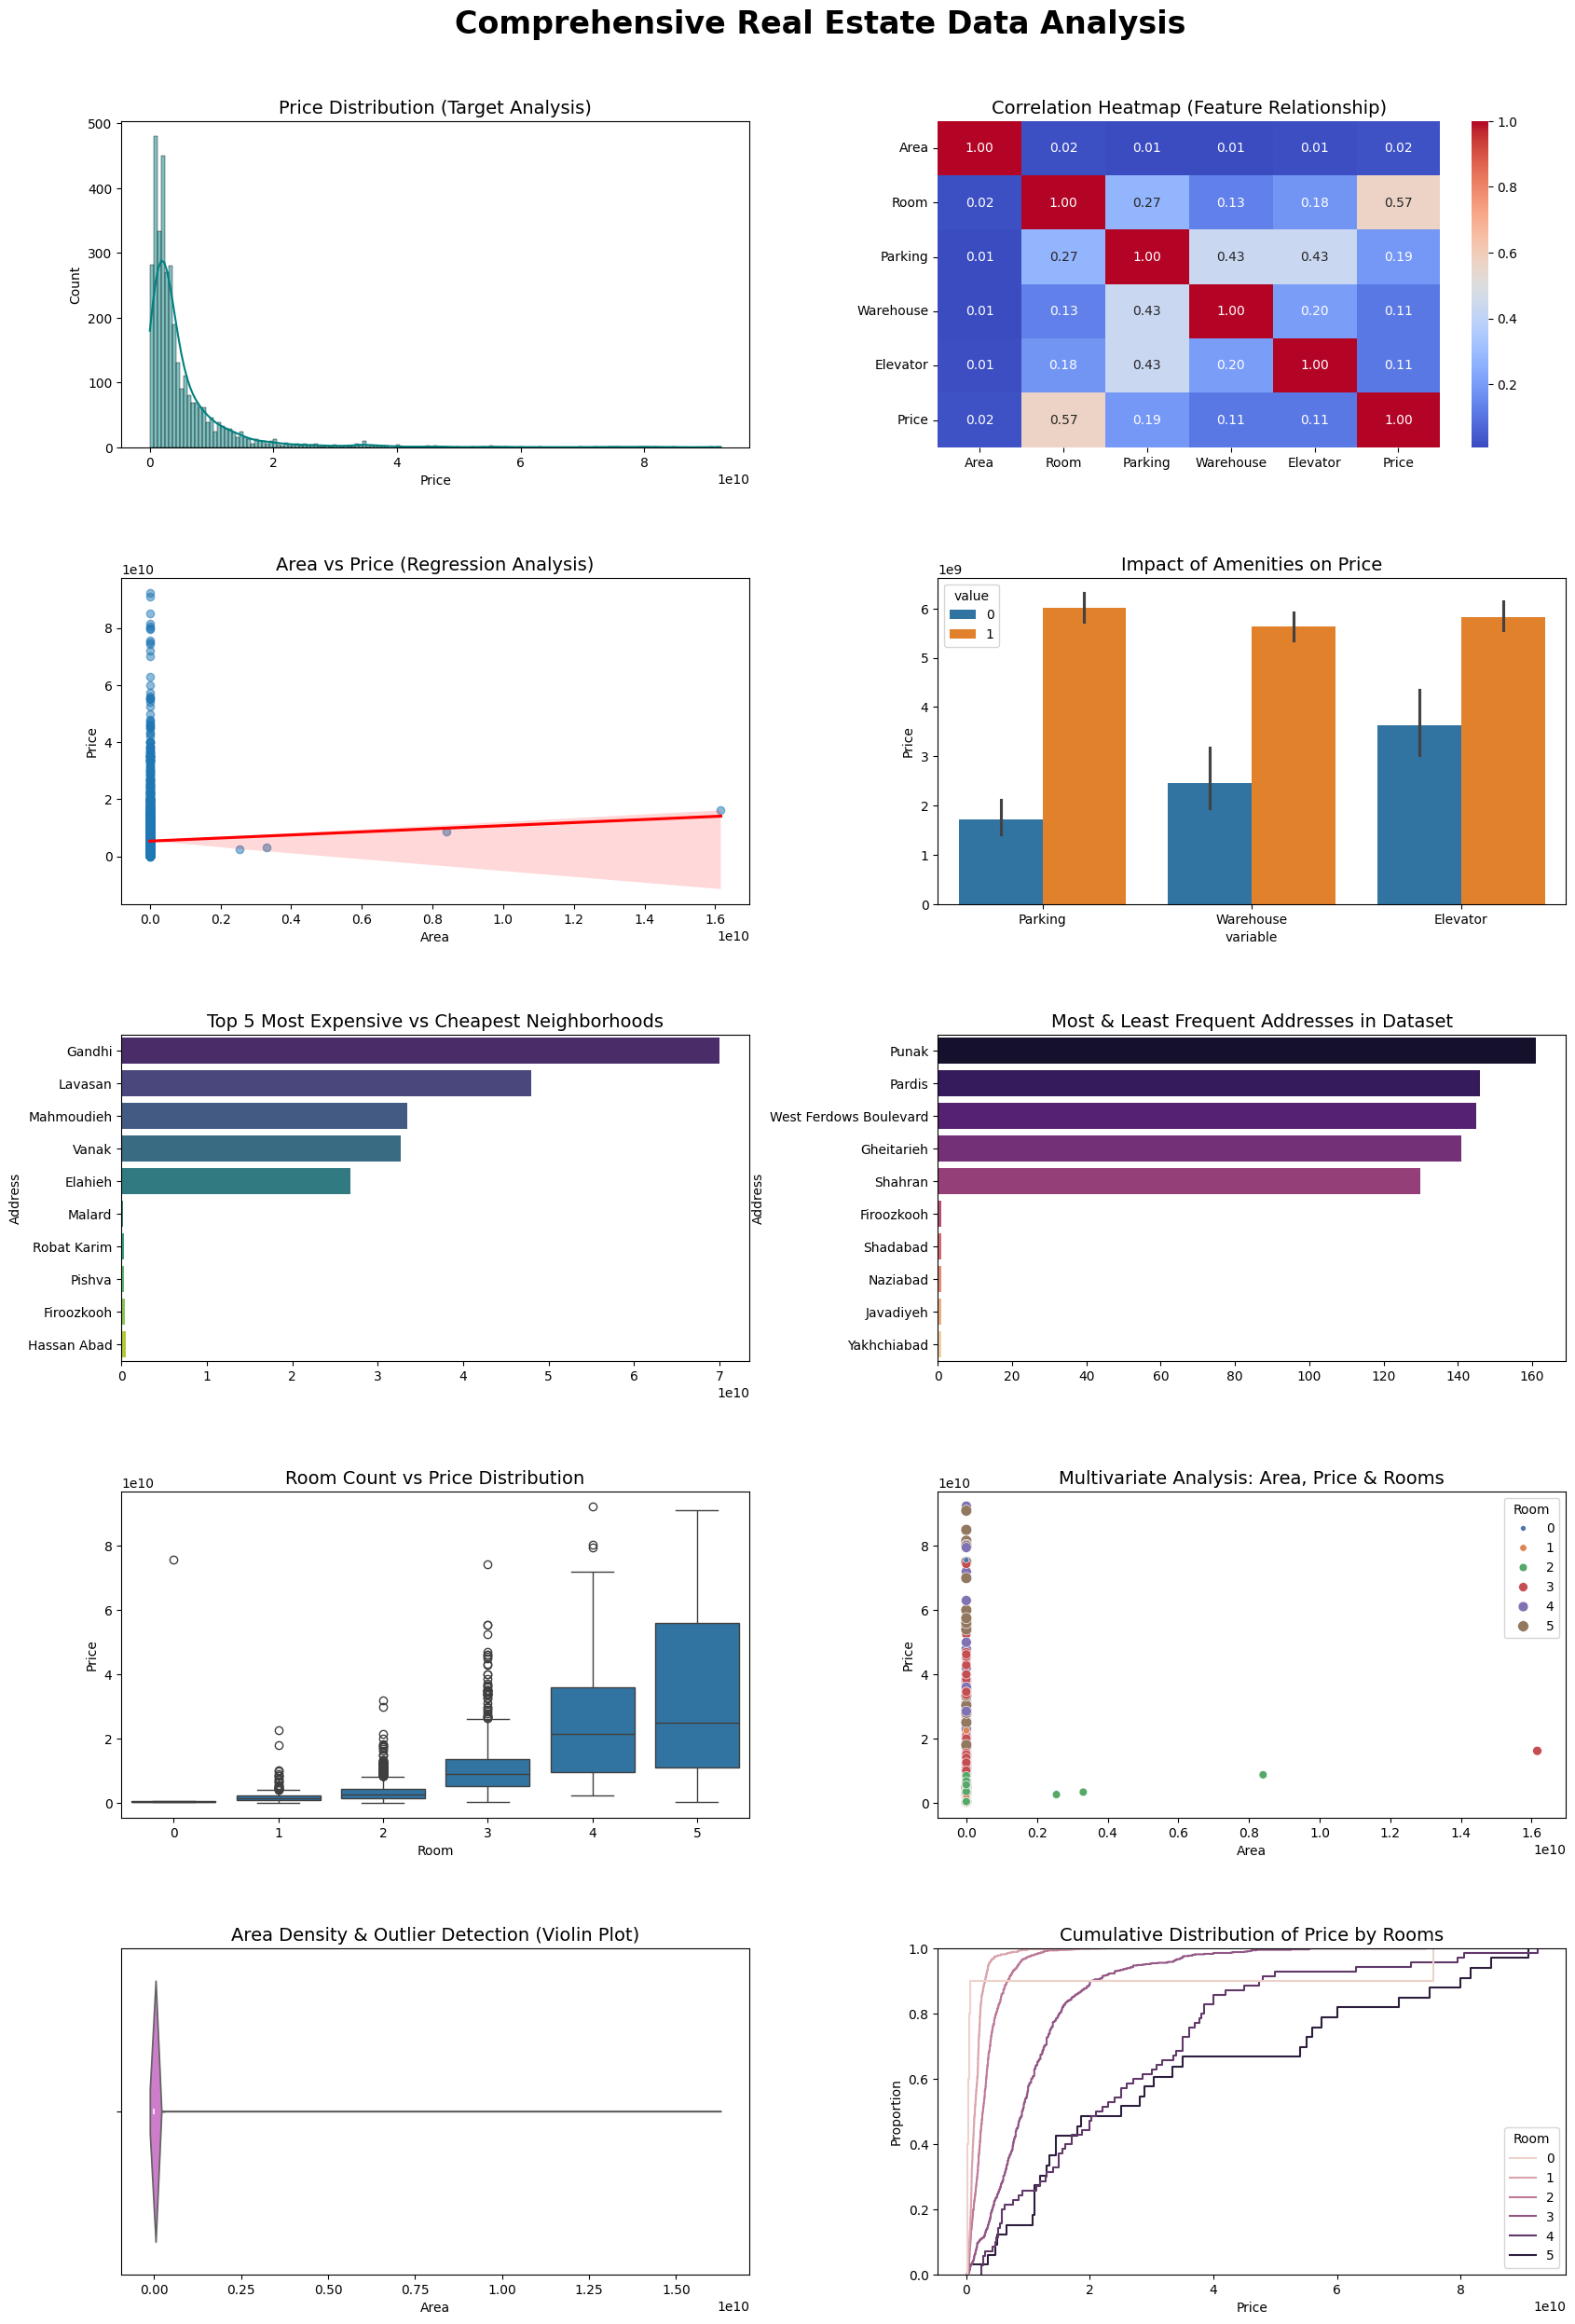

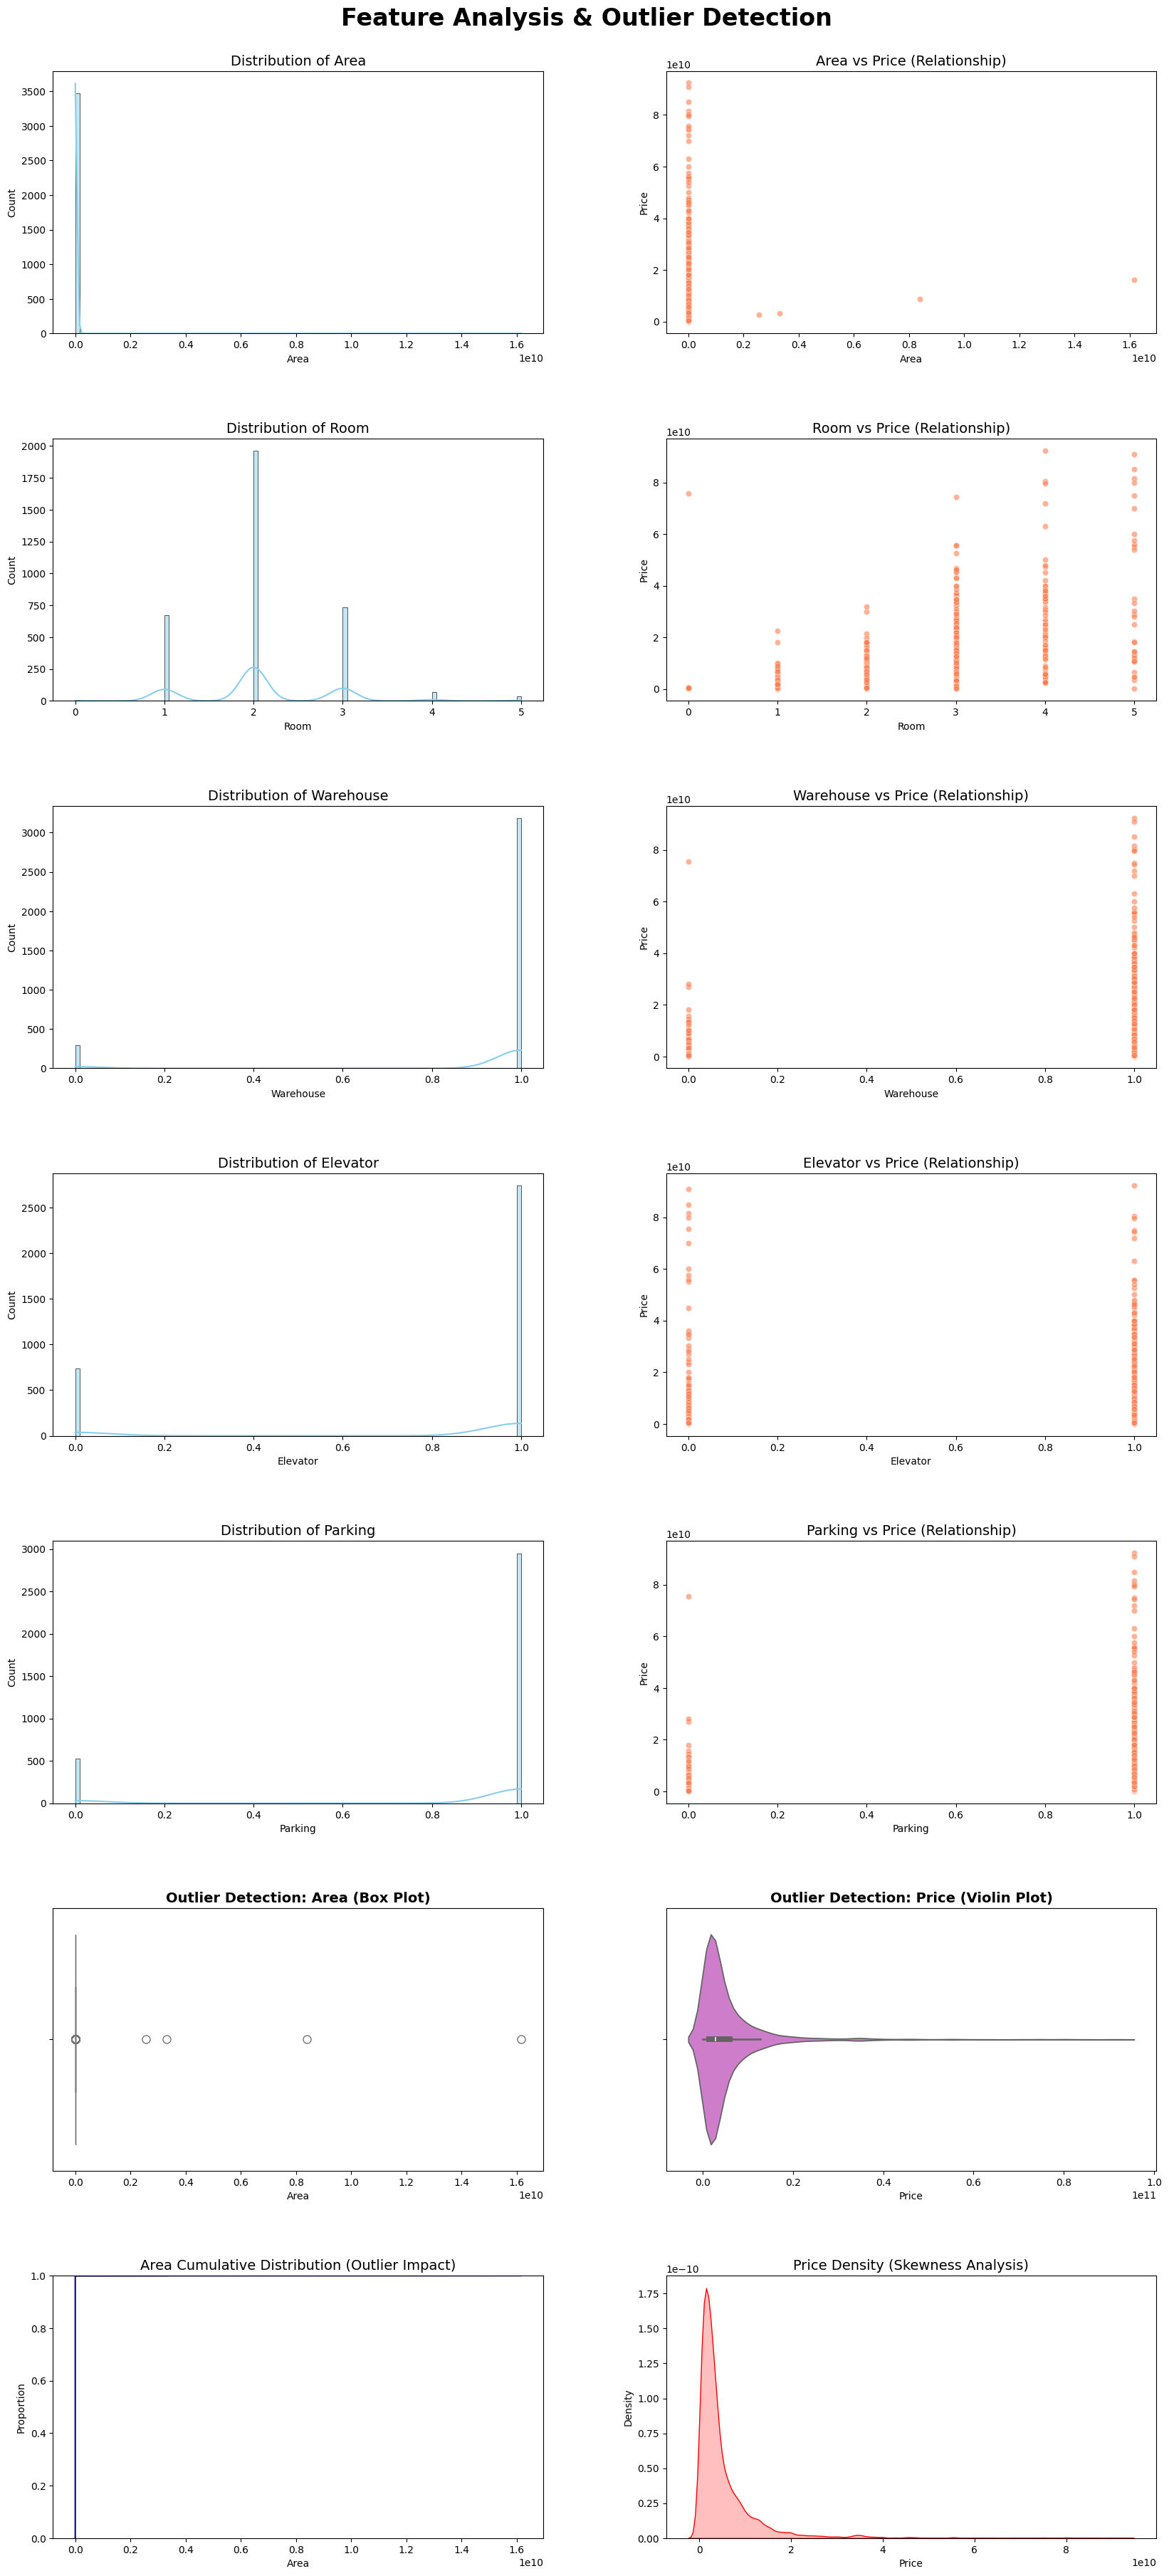

In [208]:
def data_visualization(df):
    
    fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(20, 30))
    fig.subplots_adjust(hspace=0.4, wspace=0.3)
    fig.suptitle('Comprehensive Real Estate Data Analysis', fontsize=24, fontweight='bold', y=0.92)

    sns.histplot(df['Price'], kde=True, ax=axes[0, 0], color='teal')
    axes[0, 0].set_title('Price Distribution (Target Analysis)', fontsize=14)

    corr = df.select_dtypes(include=[np.number]).corr()
    sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", ax=axes[0, 1])
    axes[0, 1].set_title('Correlation Heatmap (Feature Relationship)', fontsize=14)

    sns.regplot(data=df, x='Area', y='Price', ax=axes[1, 0], scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
    axes[1, 0].set_title('Area vs Price (Regression Analysis)', fontsize=14)

    binary_features = ['Parking', 'Warehouse', 'Elevator']
    melted_df = df.melt(id_vars='Price', value_vars=binary_features)
    sns.barplot(data=melted_df, x='variable', y='Price', hue='value', ax=axes[1, 1])
    axes[1, 1].set_title('Impact of Amenities on Price', fontsize=14)

    top_expensive = df.groupby('Address')['Price'].mean().sort_values(ascending=False).head(5)
    top_cheapest = df.groupby('Address')['Price'].mean().sort_values(ascending=True).head(5)
    address_stats = pd.concat([top_expensive, top_cheapest])
    sns.barplot(x=address_stats.values, y=address_stats.index, ax=axes[2, 0], palette='viridis')
    axes[2, 0].set_title('Top 5 Most Expensive vs Cheapest Neighborhoods', fontsize=14)

    address_counts = df['Address'].value_counts()
    top_freq = pd.concat([address_counts.head(5), address_counts.tail(5)])
    sns.barplot(x=top_freq.values, y=top_freq.index, ax=axes[2, 1], palette='magma')
    axes[2, 1].set_title('Most & Least Frequent Addresses in Dataset', fontsize=14)

    sns.boxplot(data=df, x='Room', y='Price', ax=axes[3, 0])
    axes[3, 0].set_title('Room Count vs Price Distribution', fontsize=14)

    sns.scatterplot(data=df, x='Area', y='Price', hue='Room', size='Room', palette='deep', ax=axes[3, 1])
    axes[3, 1].set_title('Multivariate Analysis: Area, Price & Rooms', fontsize=14)

    sns.violinplot(data=df, x='Area', ax=axes[4, 0], color='orchid')
    axes[4, 0].set_title('Area Density & Outlier Detection (Violin Plot)', fontsize=14)

    sns.ecdfplot(data=df, x='Price', hue='Room', ax=axes[4, 1])
    axes[4, 1].set_title('Cumulative Distribution of Price by Rooms', fontsize=14)

    
    features = ['Area', 'Room', 'Warehouse', 'Elevator', 'Parking']
    
    fig, axes = plt.subplots(nrows=7, ncols=2, figsize=(20, 45))
    fig.subplots_adjust(hspace=0.4, wspace=0.25)
    fig.suptitle('Feature Analysis & Outlier Detection', fontsize=24, fontweight='bold', y=0.9)

    for i, col in enumerate(features):
        sns.histplot(df[col], kde=True, ax=axes[i, 0],bins=100, color='skyblue')
        axes[i, 0].set_title(f'Distribution of {col}', fontsize=14)
        
        sns.scatterplot(data=df, x=col, y='Price', ax=axes[i, 1], color='coral', alpha=0.6)
        axes[i, 1].set_title(f'{col} vs Price (Relationship)', fontsize=14)

    
    sns.boxplot(x=df['Area'], ax=axes[5, 0], color='lightgreen', fliersize=8)
    axes[5, 0].set_title('Outlier Detection: Area (Box Plot)', fontsize=14, fontweight='bold')

    sns.violinplot(x=df['Price'], ax=axes[5, 1], color='orchid')
    axes[5, 1].set_title('Outlier Detection: Price (Violin Plot)', fontsize=14, fontweight='bold')

    sns.ecdfplot(data=df, x='Area', ax=axes[6, 0], color='darkblue')
    axes[6, 0].set_title('Area Cumulative Distribution (Outlier Impact)', fontsize=14)

    sns.kdeplot(data=df, x='Price', fill=True, bw_adjust=0.5, ax=axes[6, 1], color='red')
    axes[6, 1].set_title('Price Density (Skewness Analysis)', fontsize=14)

    
    return fig

fig = data_visualization(df)
plt.show()


In [209]:
df['Room'].value_counts().sort_index()

Room
0      10
1     673
2    1961
3     732
4      70
5      33
Name: count, dtype: int64

In [210]:
percentiles = [0.15 , 0.25 , 0.35 , 0.50, 0.75, 0.90, 0.95, 0.99]
df['Price'].quantile(percentiles).round()

0.15    8.785000e+08
0.25    1.418250e+09
0.35    1.958110e+09
0.50    2.900000e+09
0.75    6.000000e+09
0.90    1.200000e+10
0.95    1.765670e+10
0.99    4.000000e+10
Name: Price, dtype: float64

In [211]:
df1 = df.copy()
df = data_loader(path)
df

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
0,63,1,True,True,True,Shahran,1.850000e+09,61666.67
1,60,1,True,True,True,Shahran,1.850000e+09,61666.67
2,79,2,True,True,True,Pardis,5.500000e+08,18333.33
3,95,2,True,True,True,Shahrake Qods,9.025000e+08,30083.33
4,123,2,True,True,True,Shahrake Gharb,7.000000e+09,233333.33
...,...,...,...,...,...,...,...,...
3474,86,2,True,True,True,Southern Janatabad,3.500000e+09,116666.67
3475,83,2,True,True,True,Niavaran,6.800000e+09,226666.67
3476,75,2,False,False,False,Parand,3.650000e+08,12166.67
3477,105,2,True,True,True,Dorous,5.600000e+09,186666.67


In [212]:
df1

,Area,Room,Parking,Warehouse,Elevator,Address,Price
0,63,1,1,1,1,Shahran,1.850000e+09
1,60,1,1,1,1,Shahran,1.850000e+09
2,79,2,1,1,1,Pardis,5.500000e+08
3,95,2,1,1,1,Shahrake Qods,9.025000e+08
4,123,2,1,1,1,Shahrake Gharb,7.000000e+09
...,...,...,...,...,...,...,...
3474,86,2,1,1,1,Southern Janatabad,3.500000e+09
3475,83,2,1,1,1,Niavaran,6.800000e+09
3476,75,2,0,0,0,Parand,3.650000e+08
3477,105,2,1,1,1,Dorous,5.600000e+09


In [213]:
bins = [
    0,
    4000000000,
    10000000000,
    float("inf")
]

labels = [1, 2, 3]

df1["Price_Category"] = pd.cut(
    df["Price"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

df1['Price_Category'] = df1['Price_Category'].astype('int8')

In [214]:
df1.dropna(inplace=True)
df1.drop_duplicates(inplace=True)

In [215]:
df1.describe()

,Area,Room,Parking,Warehouse,Elevator,Price,Price_Category
count,3.248000e+03,3248.000000,3248.000000,3248.000000,3248.000000,3.248000e+03,3248.000000
mean,9.365872e+06,2.088054,0.845135,0.914101,0.785406,5.478118e+09,1.497537
std,3.277906e+08,0.764716,0.361831,0.280258,0.410603,8.267916e+09,0.715868
min,3.000000e+01,0.000000,0.000000,0.000000,0.000000,3.600000e+06,1.000000
25%,7.000000e+01,2.000000,1.000000,1.000000,1.000000,1.420000e+09,1.000000
50%,9.000000e+01,2.000000,1.000000,1.000000,1.000000,2.977500e+09,1.000000
75%,1.220000e+02,2.000000,1.000000,1.000000,1.000000,6.200000e+09,2.000000
max,1.616000e+10,5.000000,1.000000,1.000000,1.000000,9.240000e+10,3.000000


In [216]:
df1['Price_log'] = np.log10(df['Price'])

In [217]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3248 entries, 0 to 3478
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Area            3248 non-null   int64  
 1   Room            3248 non-null   int8   
 2   Parking         3248 non-null   int8   
 3   Warehouse       3248 non-null   int8   
 4   Elevator        3248 non-null   int8   
 5   Address         3248 non-null   object 
 6   Price           3248 non-null   float64
 7   Price_Category  3248 non-null   int8   
 8   Price_log       3248 non-null   float64
dtypes: float64(2), int64(1), int8(5), object(1)
memory usage: 142.7+ KB


In [218]:
# for col in df1.columns:
#     if col == 'Address' or col == 'Price':
#         continue
Q1 , Q3 = np.quantile(df1['Area'] , [0.25 , 0.75])
IQR = Q3 - Q1

upper_IQR = Q3 + 1.5 * IQR
lower_IQR = Q1 - 1.5 * IQR

df1[(df1['Area'] < lower_IQR) | (df1['Area'] > upper_IQR)]
df1

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price_Category,Price_log
0,63,1,1,1,1,Shahran,1.850000e+09,1,9.267172
1,60,1,1,1,1,Shahran,1.850000e+09,1,9.267172
2,79,2,1,1,1,Pardis,5.500000e+08,1,8.740363
3,95,2,1,1,1,Shahrake Qods,9.025000e+08,1,8.955447
4,123,2,1,1,1,Shahrake Gharb,7.000000e+09,2,9.845098
...,...,...,...,...,...,...,...,...,...
3473,63,1,1,1,0,Feiz Garden,1.890000e+09,1,9.276462
3474,86,2,1,1,1,Southern Janatabad,3.500000e+09,1,9.544068
3475,83,2,1,1,1,Niavaran,6.800000e+09,2,9.832509
3477,105,2,1,1,1,Dorous,5.600000e+09,2,9.748188


In [219]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3248 entries, 0 to 3478
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Area            3248 non-null   int64  
 1   Room            3248 non-null   int8   
 2   Parking         3248 non-null   int8   
 3   Warehouse       3248 non-null   int8   
 4   Elevator        3248 non-null   int8   
 5   Address         3248 non-null   object 
 6   Price           3248 non-null   float64
 7   Price_Category  3248 non-null   int8   
 8   Price_log       3248 non-null   float64
dtypes: float64(2), int64(1), int8(5), object(1)
memory usage: 142.7+ KB


In [220]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3479 entries, 0 to 3478
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Area        3479 non-null   object 
 1   Room        3479 non-null   int64  
 2   Parking     3479 non-null   bool   
 3   Warehouse   3479 non-null   bool   
 4   Elevator    3479 non-null   bool   
 5   Address     3456 non-null   object 
 6   Price       3479 non-null   float64
 7   Price(USD)  3479 non-null   float64
dtypes: bool(3), float64(2), int64(1), object(2)
memory usage: 146.2+ KB


In [ ]:
encoding = TargetEncoder(cols=['Address'])
df1['Address_Encoding'] = encoding.fit_transform(
    df1['Address'],
    df1['Price']
)

In [229]:
df1[['Address' , 'Address_Encoding' , 'Price_Category']]

,Address,Address_Encoding,Price_Category
0,Shahran,3.027058e+09,1
1,Shahran,3.027058e+09,1
2,Pardis,7.938730e+08,1
3,Shahrake Qods,9.367641e+08,1
4,Shahrake Gharb,1.183619e+10,2
...,...,...,...
3473,Feiz Garden,3.456825e+09,1
3474,Southern Janatabad,3.230337e+09,1
3475,Niavaran,1.973064e+10,2
3477,Dorous,9.876786e+09,2


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score

In [238]:
x = df1.drop(['Price' , 'Address'] , axis = 1)
y = df1['Price']

X_train , X_test , y_train , y_test = train_test_split(x , y , test_size= 0.2 , random_state=42 , shuffle=True)

In [242]:
model = SGDRegressor(max_iter=10)

In [243]:
model.fit(X_train , y_train)


,loss,'squared_error'
,penalty,'l2'
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,10
,tol,0.001
,shuffle,True
,verbose,0
,epsilon,0.1
,random_state,None


In [244]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print('MAE:', mae)
print('RMSE:', rmse)
print('R2 Score:', r2)

MAE: 2.9378060595787783e+28
RMSE: 3.849703437042366e+28
R2 Score: -2.605622938174617e+37
